# 第3章　ガウス過程の基礎

温度ごとの強度が共にどのように変わり得るかを、測定前の分布で表します。カーネルで有限個の入力に対する共分散を作り、数本の事前サンプルを描きます。第4章ではこの共分散行列に観測の情報を加えます。

In [1]:
import json

import matplotlib.pyplot as plt
import torch
from gpytorch.kernels import MaternKernel, RBFKernel, ScaleKernel

from experiment import BLUE, DTYPE, GREEN, ORANGE, QUALITY, save_figure, setup

setup()
inputs = torch.tensor([[0.0], [0.25], [0.75]], dtype=DTYPE)
rbf = RBFKernel().to(dtype=DTYPE)
rbf.lengthscale = 0.5
with torch.no_grad():
    covariance = rbf(inputs).to_dense()
distribution = torch.distributions.MultivariateNormal(
    torch.zeros(3, dtype=DTYPE), covariance_matrix=covariance,
)
print("共分散行列:")
print(covariance)
print("3つの温度での潜在値を1組サンプル:")
print(distribution.sample())

共分散行列:
tensor([[1.0000, 0.8825, 0.3247],
        [0.8825, 1.0000, 0.6065],
        [0.3247, 0.6065, 1.0000]], dtype=torch.float64)
3つの温度での潜在値を1組サンプル:
tensor([0.3655, 1.2192, 1.5584], dtype=torch.float64)


## 3.4・3.5 カーネルと長さ尺度で事前分布を比べる
平均70 MPa、各点の標準偏差12 MPaとし、121個の同じ温度で事前分布からサンプルします。共通の標準正規乱数を各共分散のCholesky因子で変換します。共分散への対角補正は $10^{-8}\,\mathrm{MPa}^2$ で、密な格子での数値計算に使います。

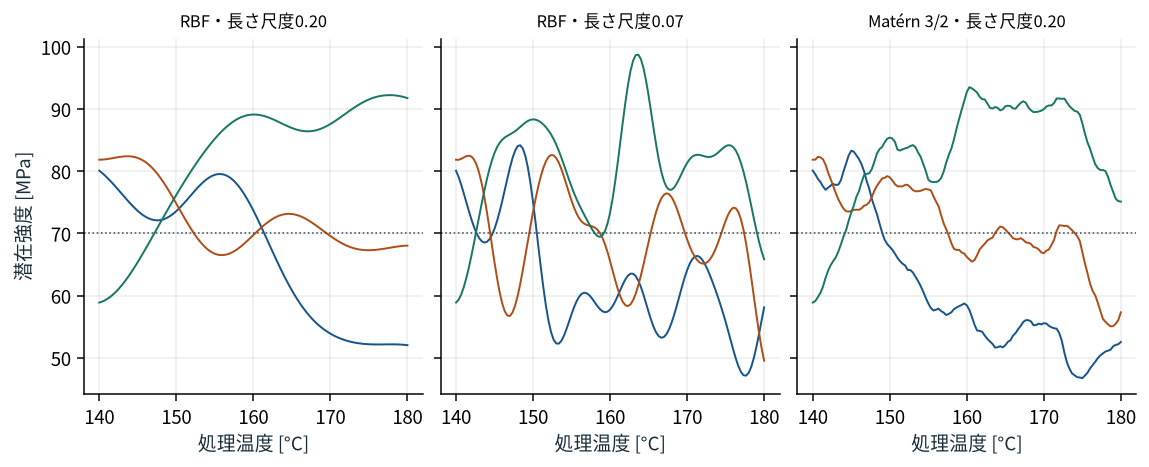

In [2]:
grid = torch.linspace(0, 1, 121, dtype=DTYPE).unsqueeze(-1)
eye = torch.eye(len(grid), dtype=DTYPE)
white_noise = torch.randn((len(grid), 3), dtype=DTYPE)
settings = (
    ("RBF・長さ尺度0.20", RBFKernel(), 0.20),
    ("RBF・長さ尺度0.07", RBFKernel(), 0.07),
    ("Matérn 3/2・長さ尺度0.20", MaternKernel(nu=1.5), 0.20),
)
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.35), sharey=True, layout="constrained")
for ax, (label, base, ell) in zip(axes, settings):
    kernel = ScaleKernel(base).to(dtype=DTYPE)
    kernel.base_kernel.lengthscale = ell
    kernel.outputscale = 12.0**2
    with torch.no_grad():
        k = kernel(grid).to_dense()
        torch.testing.assert_close(k.diagonal(), torch.full((len(grid),), 144.0, dtype=DTYPE))
        factor = torch.linalg.cholesky(k + 1e-8 * eye)
        paths = 70.0 + factor @ white_noise
    for path, color in zip(paths.T, (BLUE, ORANGE, GREEN)):
        ax.plot(140 + 40 * grid[:, 0], path, color=color, linewidth=1.05)
    ax.axhline(70.0, color="#45515b", linewidth=0.85, linestyle=":")
    ax.set_title(label, fontsize=8.8)
    ax.set_xlabel("処理温度 [°C]")
axes[0].set_ylabel("潜在強度 [MPa]")
save_figure(fig, "ch03_prior_paths")

## 3.6 次章の行列を作る
第4章の手計算と同じ順 $X=(0,1)$、$X_*=(0.25,0.75)$ でRBF共分散を作ります。この小例は無次元で振幅分散1、長さ尺度0.5です。上左ブロックが観測位置同士、右上が観測位置と予測位置の共分散です。観測ノイズは第4章で観測側の対角に加えます。

tensor([[1.0000, 0.1353, 0.8825, 0.3247],
        [0.1353, 1.0000, 0.3247, 0.8825],
        [0.8825, 0.3247, 1.0000, 0.6065],
        [0.3247, 0.8825, 0.6065, 1.0000]], dtype=torch.float64)


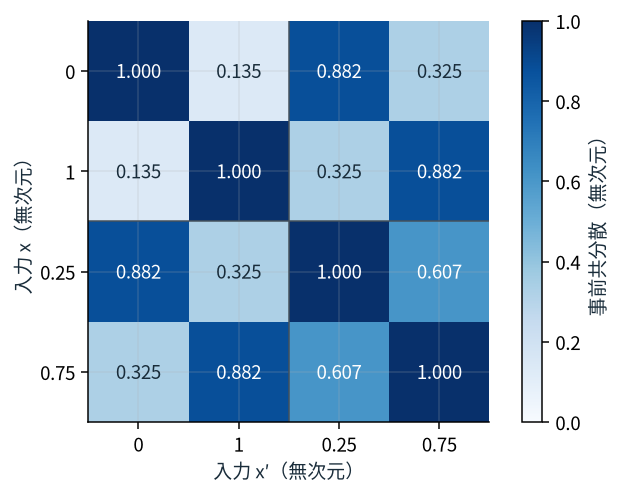

In [3]:
joined = torch.tensor([[0.0], [1.0], [0.25], [0.75]], dtype=DTYPE)
with torch.no_grad():
    full = rbf(joined).to_dense()
    exact = torch.exp(-0.5 * torch.cdist(joined, joined).square() / 0.5**2)
torch.testing.assert_close(full, exact, rtol=1e-10, atol=1e-12)
fig, ax = plt.subplots(figsize=(5.8, 3.55), layout="constrained")
image = ax.imshow(full.numpy(), vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(4), ["0", "1", "0.25", "0.75"])
ax.set_yticks(range(4), ["0", "1", "0.25", "0.75"])
ax.set(xlabel="入力 x′（無次元）", ylabel="入力 x（無次元）")
ax.axvline(1.5, color="#45515b", linewidth=0.8)
ax.axhline(1.5, color="#45515b", linewidth=0.8)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{full[i,j]:.3f}", ha="center", va="center",
                color="white" if full[i,j] > 0.57 else "#192c3a")
fig.colorbar(image, ax=ax, label="事前共分散（無次元）")
save_figure(fig, "ch03_covariance_blocks")
metrics = {"fixed_input_order": joined[:, 0].tolist(), "fixed_prior_covariance": full.tolist()}
(QUALITY / "ch03_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
print(full)

## 章末演習
1. **確認。** 分散1、長さ尺度0.5のRBFで、$x=0$ と $x'=0.5$ の共分散を求めましょう。
2. **操作。** RBFの長さ尺度0.20を0.40に変え、同じ図の見た目と共分散がどう変わるか確かめましょう。
3. **発展。** $X=(0,1)$ に対する観測ノイズの分散を0.1とします。第4章のために、共分散行列のどの対角成分に0.1を足すか示してください。